# Fragment-Based Analysis of Natural Product vs Synthetic Chelators
**Dataset:** Feeney et al. 2026 – `ao6c06383_si_001.csv`  
**Classification:** Non-empty `NP info` → Natural Product chelator (NC); empty → Synthetic chelator (SC)  
**Method:** SMILES preprocessing · BRICS fragmentation · Morgan fingerprints · Fisher enrichment & Bonferroni · Tanimoto diversity  
**Date:** 2026-11-04


## 0. Imports and Configuration

In [2]:
import warnings, random, os, time, signal, pickle
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib_venn import venn2
import seaborn as sns
from collections import Counter
from itertools import combinations
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import AllChem, Draw, BRICS, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.rdmolops import GetMolFrags

# Silence RDKit's per-molecule warnings (thousands of lines otherwise flood the notebook)
RDLogger.DisableLog("rdApp.*")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

# Ensure output directory exists before any savefig calls
os.makedirs("plots", exist_ok=True)

DATA_PATH = "ao6c06383_si_001.csv"
ORGANIC_ATOMS = {1,5,6,7,8,9,14,15,16,17,34,35,53}  # H B C N O F Si P S Cl Se Br I
print("All imports successful.")


All imports successful.


## 1. Data Loading & Classification

Raw rows: 35,548  |  Columns: ['smiles', 'database', 'database ID', 'NP info', 'denticity', 'metal', 'type', 'name'] ...

Raw class counts:
class
SC    32762
NC     2786


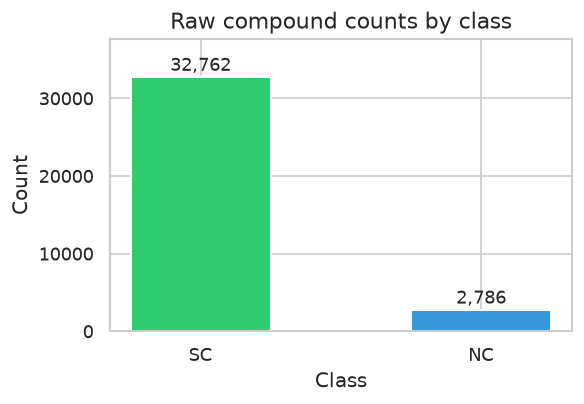

In [3]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)   # low_memory=False: columns have mixed types
print(f"Raw rows: {len(df_raw):,}  |  Columns: {list(df_raw.columns[:8])} ...")

# Strip whitespace from column names
df_raw.columns = df_raw.columns.str.strip()

# Classification: non-empty 'NP info' → NC, else SC
def classify(val):
    if pd.notna(val) and str(val).strip() != "":
        return "NC"
    return "SC"

df_raw["class"] = df_raw["NP info"].apply(classify)
counts_raw = df_raw["class"].value_counts()
print("\nRaw class counts:")
print(counts_raw.to_string())

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts_raw.index, counts_raw.values,
              color=["#2ecc71", "#3498db"], edgecolor="white", linewidth=1.2, width=0.5)
for bar, v in zip(bars, counts_raw.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 200, f"{v:,}",
            ha="center", va="bottom") #, fontweight="bold"
ax.set_title("Raw compound counts by class", fontsize=13) #, fontweight="bold"
ax.set_xlabel("Class"); ax.set_ylabel("Count")
ax.set_ylim(0, counts_raw.values.max() * 1.15)
plt.tight_layout(); plt.savefig("plots/01_raw_class_counts.png", bbox_inches="tight"); plt.show()


## 2. SMILES Preprocessing Pipeline
Steps applied in order:
1. Parse SMILES → RDKit Mol  
2. Disconnect organometallic bonds (MetalDisconnector)  
3. Remove metal atoms (keep only organic atoms)  
4. Select largest fragment  
5. Sanitize & canonicalise  
6. Deduplicate within-class, then drop cross-class duplicates entirely


In [4]:
disconnector = rdMolStandardize.MetalDisconnector()

def preprocess_smiles(smi):
    """Return canonical SMILES of the cleaned organic fragment, or None on failure."""
    try:
        mol = Chem.MolFromSmiles(str(smi))
        if mol is None:
            return None
        # Disconnect organometallic bonds
        mol = disconnector.Disconnect(mol)
        # Remove metal atoms
        edit = Chem.RWMol(mol)
        atoms_to_remove = sorted(
            [a.GetIdx() for a in edit.GetAtoms() if a.GetAtomicNum() not in ORGANIC_ATOMS],
            reverse=True
        )
        for idx in atoms_to_remove:
            edit.RemoveAtom(idx)
        mol = edit.GetMol()
        if mol is None or mol.GetNumAtoms() == 0:
            return None
        # Largest fragment
        frags = GetMolFrags(mol, asMols=True, sanitizeFrags=True)
        if not frags:
            return None
        mol = max(frags, key=lambda m: m.GetNumHeavyAtoms())
        # Sanitize & canonicalize
        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        return None

df_raw["canon_smi"] = df_raw["smiles"].apply(preprocess_smiles)
n_failed = df_raw["canon_smi"].isna().sum()
print(f"Failed to parse/process: {n_failed:,} rows")

df = df_raw.dropna(subset=["canon_smi"]).copy()
print(f"Remaining after parse: {len(df):,}")
n_parse_ok = len(df)

# Within-class deduplication
before_wd = len(df)
df = df.drop_duplicates(subset=["class", "canon_smi"])
print(f"After within-class dedup: {len(df):,}  (removed {before_wd - len(df):,})")
n_within = len(df)

# Cross-class deduplication: find SMILES appearing in both classes
cross = df.groupby("canon_smi")["class"].nunique()
cross_dups = cross[cross > 1].index
print(f"Cross-class duplicate SMILES (same molecule in NC & SC): {len(cross_dups):,}")
df = df[~df["canon_smi"].isin(cross_dups)].copy()
print(f"After cross-class dedup:   {len(df):,}")

class_counts = df["class"].value_counts()
print("\nFinal class counts:")
print(class_counts.to_string())


Failed to parse/process: 16 rows
Remaining after parse: 35,532
After within-class dedup: 35,423  (removed 109)
Cross-class duplicate SMILES (same molecule in NC & SC): 7
After cross-class dedup:   35,409

Final class counts:
class
SC    32706
NC     2703


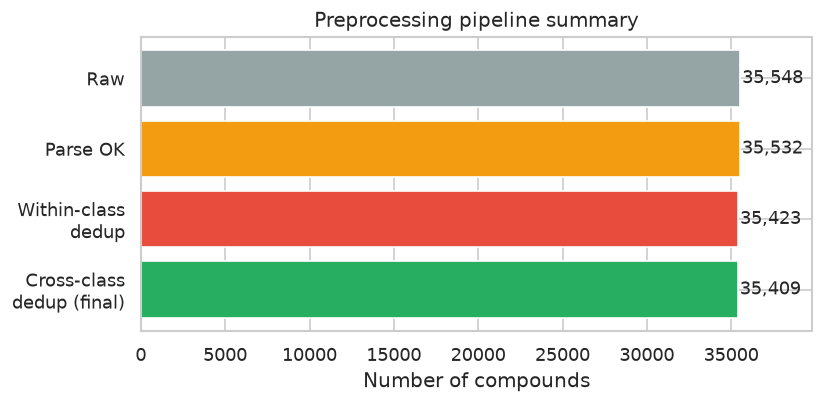

In [5]:
stages = ["Raw", "Parse OK", "Within-class\ndedup", "Cross-class\ndedup (final)"]
values = [len(df_raw), n_parse_ok, n_within, len(df)]

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ["#95a5a6","#f39c12","#e74c3c","#27ae60"]
bars = ax.barh(stages[::-1], values[::-1], color=colors[::-1], edgecolor="white")
for bar, v in zip(bars, values[::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
            f"{v:,}", va="center") #, fontweight="bold"
ax.set_xlabel("Number of compounds"); ax.set_title("Preprocessing pipeline summary") #, fontweight="bold"
ax.set_xlim(0, max(values) * 1.12)
plt.tight_layout(); plt.savefig("plots/02_preprocessing_funnel.png", bbox_inches="tight"); plt.show()

## 3. BRICS Fragmentation

A safeguard is appllied here to avoid kernel crash. The cell below keeps the **same BRICS method and
`minFragmentSize`** as before, but adds safeguards:

* molecules with more than `MAX_BRICS_BONDS` cleavable bonds are skipped (counted with `FindBRICSBonds`, which is cheap);
* a per-molecule time limit (`BRICS_TIMEOUT_S`, Linux/macOS only);
* progress printing and a checkpoint file (`brics_cache.pkl`), so a restart does not repeat finished work.

Any molecule that is skipped is listed and removed from the downstream analysis.

In [6]:
# ---- BRICS settings -------------------------------------------------------
MIN_FRAG_SIZE   = 3      # min heavy atoms per fragment (unchanged from the original analysis)
MAX_BRICS_BONDS = 40     # skip molecules with more BRICS-cleavable bonds than this
BRICS_TIMEOUT_S = 60     # per-molecule wall-clock limit (Linux/macOS; ignored on Windows)
USE_BRICS_CACHE = True   # checkpoint results to disk; set False to force a full re-run
BRICS_CACHE     = "brics_cache.pkl" # if not available, will be created in the current working directory and this cell will take a few minutes to run the first time (subsequent runs will be faster)

class _BRICSTimeout(Exception):
    pass

def _on_alarm(signum, frame):
    raise _BRICSTimeout()

_CAN_TIMEOUT = hasattr(signal, "SIGALRM")
if _CAN_TIMEOUT:
    try:
        signal.signal(signal.SIGALRM, _on_alarm)
    except ValueError:            # not running in the main thread
        _CAN_TIMEOUT = False

def get_brics_fragments(smi):
    """Return (set of canonical BRICS fragment SMILES, status).
    status is one of: 'ok', 'too_many_bonds', 'timeout', 'error'."""
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return set(), "error"
    if len(list(BRICS.FindBRICSBonds(mol))) > MAX_BRICS_BONDS:
        return set(), "too_many_bonds"
    try:
        if _CAN_TIMEOUT:
            signal.alarm(BRICS_TIMEOUT_S)
        frags = BRICS.BRICSDecompose(mol, returnMols=False, minFragmentSize=MIN_FRAG_SIZE)
        result = set()
        for f in frags:
            m = Chem.MolFromSmiles(f)
            if m:
                result.add(Chem.MolToSmiles(m, canonical=True))
        return result, "ok"
    except _BRICSTimeout:
        return set(), "timeout"
    except Exception:
        return set(), "error"
    finally:
        if _CAN_TIMEOUT:
            signal.alarm(0)

def run_brics(smiles, every=5000):
    """Fragment every SMILES, with progress printing and on-disk checkpoints."""
    params = (MIN_FRAG_SIZE, MAX_BRICS_BONDS)
    cache = {}
    if USE_BRICS_CACHE and os.path.exists(BRICS_CACHE):
        try:
            with open(BRICS_CACHE, "rb") as fh:
                saved = pickle.load(fh)
            if saved.get("params") == params:
                cache = saved["data"]
                print(f"Loaded {len(cache):,} cached results from {BRICS_CACHE}")
        except Exception:
            cache = {}

    def _save():
        if not USE_BRICS_CACHE:
            return
        tmp = BRICS_CACHE + ".tmp"
        with open(tmp, "wb") as fh:
            pickle.dump({"params": params, "data": cache}, fh)
        os.replace(tmp, BRICS_CACHE)

    results = {s: cache[s] for s in smiles if s in cache}
    todo = [s for s in dict.fromkeys(smiles) if s not in results]
    print(f"BRICS fragmentation: {len(todo):,} molecules to process ({len(results):,} from cache)")
    t0 = time.time()
    for k, smi in enumerate(todo, 1):
        res = get_brics_fragments(smi)
        results[smi] = res
        if res[1] != "timeout":          # do not cache timeouts (machine-dependent)
            cache[smi] = res
        if k % every == 0:
            _save()
            print(f"  {k:,}/{len(todo):,} done  ({time.time() - t0:.0f} s)", flush=True)
    _save()
    print(f"  finished in {time.time() - t0:.0f} s")
    return results

smiles_all = df["canon_smi"].tolist()
brics_res = run_brics(smiles_all)
df["brics_frags"]  = [brics_res[s][0] for s in smiles_all]
df["brics_status"] = [brics_res[s][1] for s in smiles_all]

print("\nBRICS status counts:")
print(df["brics_status"].value_counts().to_string())

# Remove molecules that could not be fragmented safely (reported, not silently dropped)
excluded = df[df["brics_status"] != "ok"]
if len(excluded):
    info = pd.DataFrame({
        "class": excluded["class"],
        "status": excluded["brics_status"],
        "heavy_atoms": [Chem.MolFromSmiles(s).GetNumHeavyAtoms() for s in excluded["canon_smi"]],
    })
    print(f"\nExcluded {len(excluded)} molecule(s) from the fragment analysis:")
    print(info.to_string())
df = df[df["brics_status"] == "ok"].copy()
n_brics_excluded = len(excluded)
class_counts = df["class"].value_counts()

nc_frags_lists = df.loc[df["class"] == "NC", "brics_frags"].tolist()
sc_frags_lists = df.loc[df["class"] == "SC", "brics_frags"].tolist()

nc_counter = Counter(f for frags in nc_frags_lists for f in frags)
sc_counter = Counter(f for frags in sc_frags_lists for f in frags)

nc_unique = set(nc_counter)
sc_unique = set(sc_counter)
shared = nc_unique & sc_unique

print(f"\nNC molecules:        {class_counts.get('NC', 0):,}")
print(f"SC molecules:        {class_counts.get('SC', 0):,}")
print(f"NC unique fragments: {len(nc_unique):,}")
print(f"SC unique fragments: {len(sc_unique):,}")
print(f"Shared fragments:    {len(shared):,}")
print(f"NC-exclusive:        {len(nc_unique - sc_unique):,}")
print(f"SC-exclusive:        {len(sc_unique - nc_unique):,}")

Loaded 35,409 cached results from brics_cache.pkl
BRICS fragmentation: 0 molecules to process (35,409 from cache)
  finished in 0 s

BRICS status counts:
brics_status
ok                35403
error                 4
too_many_bonds        2

Excluded 6 molecule(s) from the fragment analysis:
      class          status  heavy_atoms
13141    SC           error           10
16724    SC  too_many_bonds          184
24115    SC  too_many_bonds          200
28375    SC           error           14
28867    SC           error            8
30290    SC           error            9

NC molecules:        2,703
SC molecules:        32,700
NC unique fragments: 2,980
SC unique fragments: 29,569
Shared fragments:    776
NC-exclusive:        2,204
SC-exclusive:        28,793


## 4. Morgan Fingerprints for Fragments (radius=2, nBits=2048)

In [7]:
all_frags = list(nc_unique | sc_unique)

# Generator API (replaces the deprecated GetMorganFingerprintAsBitVect; same bit vectors)
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def frag_fp(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    return morgan_gen.GetFingerprint(mol)

print(f"Computing fingerprints for {len(all_frags):,} unique fragments...")
fp_dict = {}
for smi in all_frags:
    fp = frag_fp(smi)
    if fp is not None:
        fp_dict[smi] = fp

print(f"Fingerprints computed: {len(fp_dict):,}")


Computing fingerprints for 31,773 unique fragments...
Fingerprints computed: 31,773


## 5. Shared vs Class-Enriched Fragments (Fisher's Exact Test)

In [8]:
nc_total = sum(nc_counter.values())
sc_total = sum(sc_counter.values())

# Most fragments are rare, so many share identical (NC count, SC count) pairs;
# cache p-values per pair (identical results, far fewer tests to run).
_p_cache = {}
def fisher_p(a, b):
    key = (a, b)
    if key not in _p_cache:
        _, p = fisher_exact([[a, b], [nc_total - a, sc_total - b]], alternative="two-sided")
        _p_cache[key] = p
    return _p_cache[key]

results = []
all_keys = nc_unique | sc_unique
for frag in all_keys:
    a = nc_counter.get(frag, 0)   # NC count
    b = sc_counter.get(frag, 0)   # SC count
    pval = fisher_p(a, b)
    enrich = (a / nc_total) / (b / sc_total + 1e-9)
    results.append({
        "fragment": frag,
        "NC_count": a, "SC_count": b,
        "NC_freq": a / nc_total, "SC_freq": b / sc_total,
        "enrichment_ratio": enrich,
        "log2_enrichment": np.log2(enrich + 1e-9),
        "pval": pval,
        "in_NC": a > 0, "in_SC": b > 0,
    })

enrich_df = pd.DataFrame(results)
# Bonferroni correction
_, pval_adj, _, _ = multipletests(enrich_df["pval"], method="bonferroni")
enrich_df["pval_adj"] = pval_adj
enrich_df["neg_log10_pval"] = -np.log10(enrich_df["pval_adj"].clip(lower=1e-300))
enrich_df["significant"] = enrich_df["pval_adj"] < 0.05

nc_enriched = enrich_df[(enrich_df["in_NC"]) & (enrich_df["log2_enrichment"] > 1) &
                         (enrich_df["significant"])].sort_values("NC_freq", ascending=False)
sc_enriched = enrich_df[(enrich_df["in_SC"]) & (enrich_df["log2_enrichment"] < -1) &
                         (enrich_df["significant"])].sort_values("SC_freq", ascending=False)

print(f"Significantly enriched in NC:  {len(nc_enriched):,}")
print(f"Significantly enriched in SC:  {len(sc_enriched):,}")
print(f"Significant total:             {enrich_df['significant'].sum():,}")


Significantly enriched in NC:  161
Significantly enriched in SC:  24
Significant total:             185


## 6. Fragment Diversity (Tanimoto-based)

In [9]:
def tanimoto_diversity(smiles_list, fp_dict, max_n=2000, seed=SEED):
    """Mean pairwise Tanimoto distance for a sample of fragments."""
    fps = [fp_dict[s] for s in smiles_list if s in fp_dict]
    if len(fps) < 2:
        return np.array([0.0])
    if len(fps) > max_n:
        rng = np.random.default_rng(seed)
        idx = rng.choice(len(fps), max_n, replace=False)
        fps = [fps[i] for i in idx]
    # numpy arrays (not a Python list of ~2M floats) keep memory use low
    sims = [1.0 - np.asarray(DataStructs.BulkTanimotoSimilarity(fps[i], fps[i+1:]), dtype=np.float32)
            for i in range(len(fps) - 1)]
    return np.concatenate(sims)

nc_frag_list = list(nc_unique & fp_dict.keys())
sc_frag_list = list(sc_unique & fp_dict.keys())

print("Computing NC fragment diversity...")
nc_div = tanimoto_diversity(nc_frag_list, fp_dict)
print("Computing SC fragment diversity...")
sc_div = tanimoto_diversity(sc_frag_list, fp_dict)

div_summary = pd.DataFrame({
    "Class": ["NC", "SC"],
    "Unique fragments": [len(nc_frag_list), len(sc_frag_list)],
    "Mean Tanimoto dist": [nc_div.mean(), sc_div.mean()],
    "Median": [np.median(nc_div), np.median(sc_div)],
    "10th pct": [np.percentile(nc_div, 10), np.percentile(sc_div, 10)],
    "90th pct": [np.percentile(nc_div, 90), np.percentile(sc_div, 90)],
})
print("\n", div_summary.to_string(index=False))


Computing NC fragment diversity...
Computing SC fragment diversity...

 Class  Unique fragments  Mean Tanimoto dist   Median  10th pct  90th pct
   NC              2980            0.914912 0.934426  0.826087  0.978261
   SC             29569            0.925551 0.935897  0.857143  0.981132


## 7. Visualisations

### 7a. Venn Diagram – Fragment Overlap

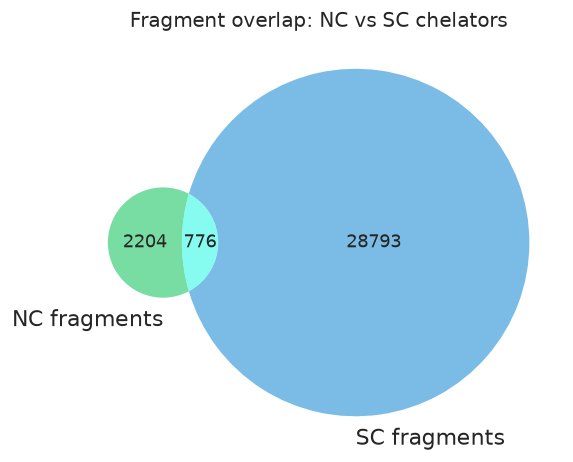

Only in NC:  2,204
Shared:      776
Only in SC:  28,793


In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
v = venn2([nc_unique, sc_unique], set_labels=("NC fragments", "SC fragments"), ax=ax,
          set_colors=("#2ecc71", "#3498db"), alpha=0.65)
ax.set_title("Fragment overlap: NC vs SC chelators") #, fontweight="bold"
plt.tight_layout(); plt.savefig("plots/03_venn_fragments.png", bbox_inches="tight"); plt.show()
print(f"Only in NC:  {len(nc_unique - sc_unique):,}")
print(f"Shared:      {len(shared):,}")
print(f"Only in SC:  {len(sc_unique - nc_unique):,}")


### 7b. Top Enriched Fragments per Class

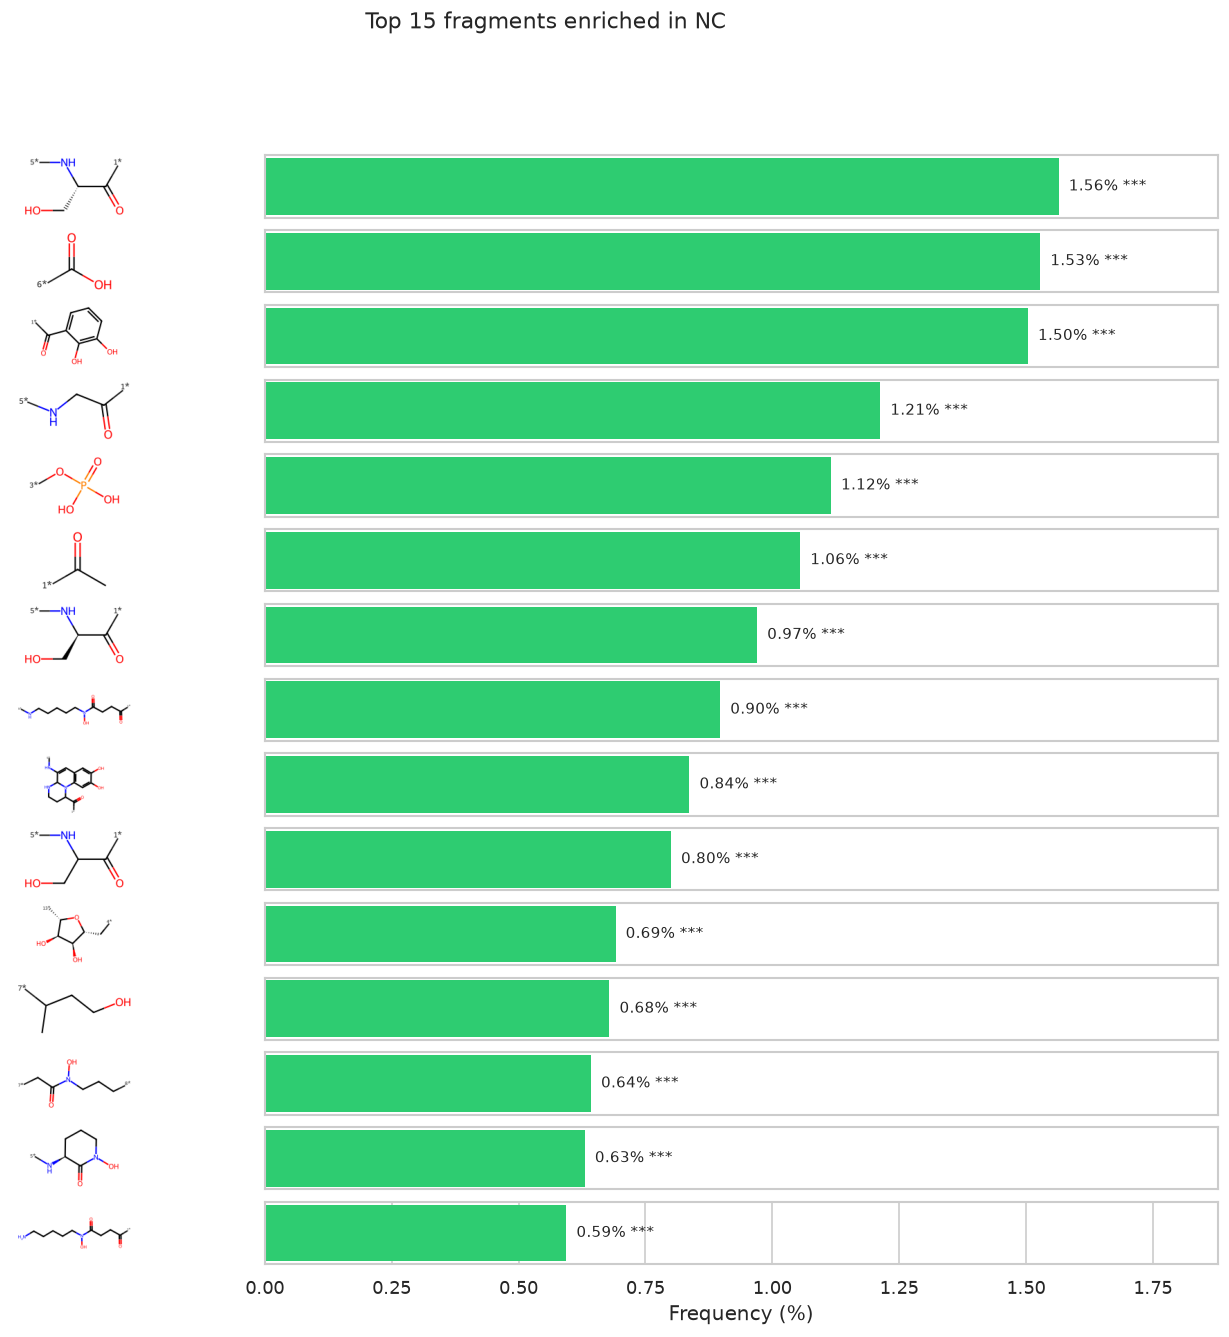

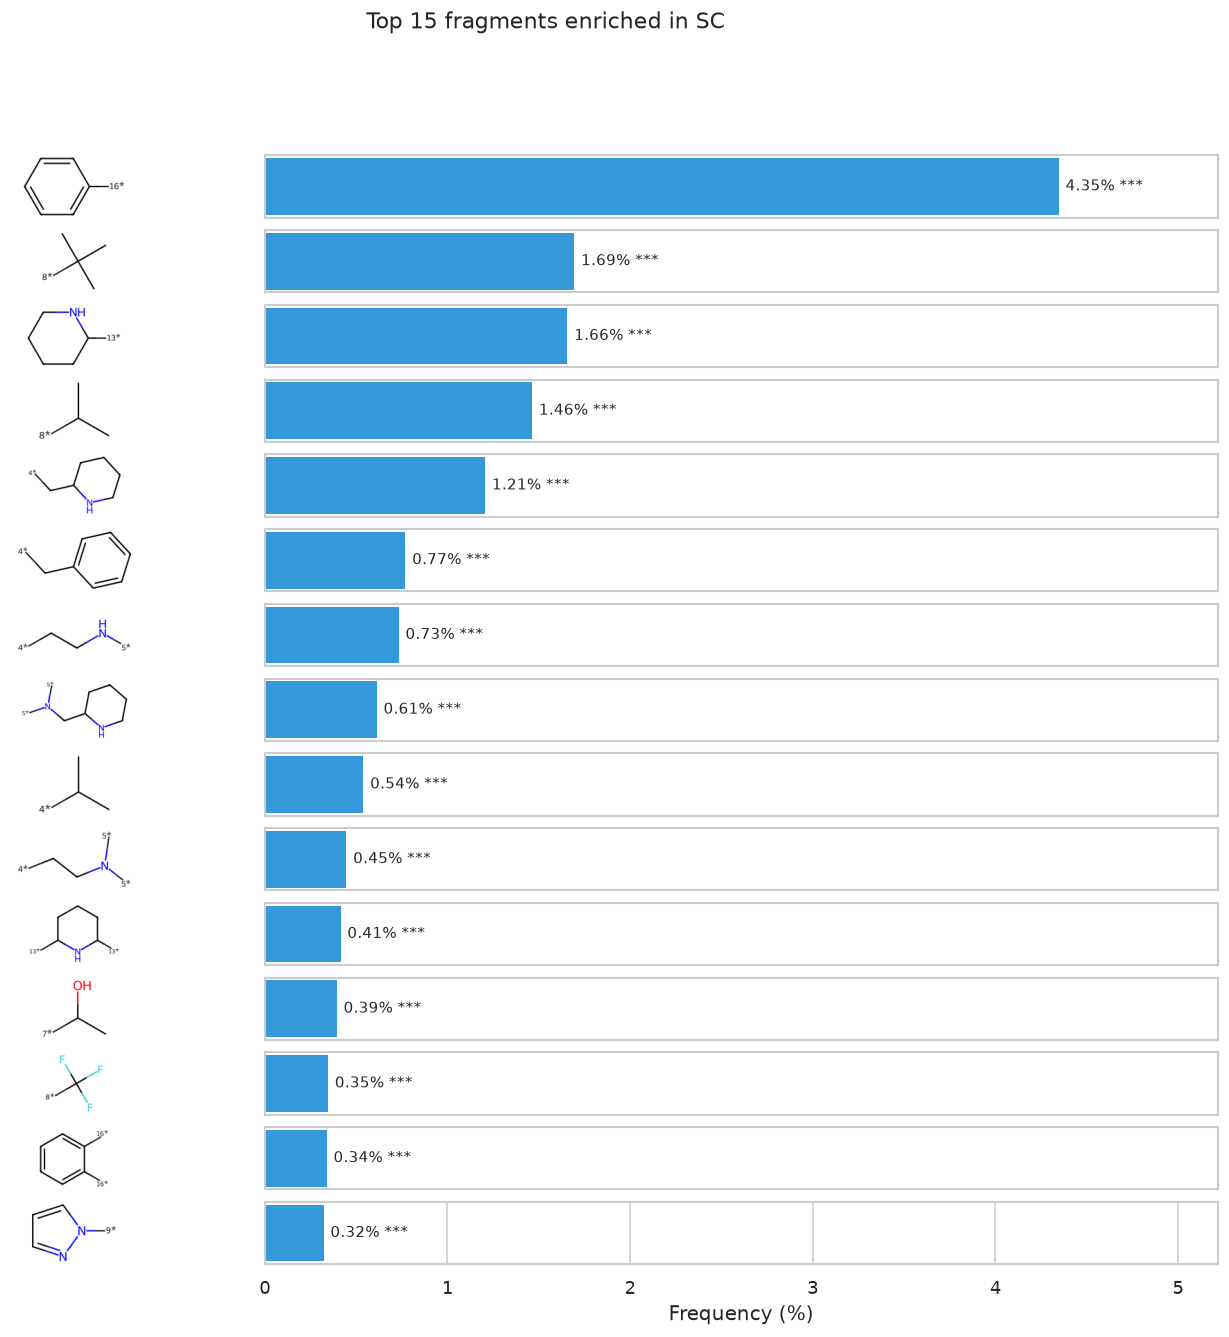

In [11]:
def draw_top_frags(enriched, counter, class_label, color, top_n=15, fname=None):
    top = enriched.head(top_n)
    if len(top) == 0:
        print(f"No significantly enriched fragments to draw for {class_label}.")
        return
    top_n = len(top)
    fig = plt.figure(figsize=(14, top_n * 0.7 + 1.5))
    gs = gridspec.GridSpec(top_n, 2, width_ratios=[1, 3], wspace=0.05)
    fig.suptitle(f"Top {top_n} fragments enriched in {class_label}", fontsize=13) #, fontweight="bold"
    for i, row in enumerate(top.itertuples()):
        smi = row.fragment
        mol = Chem.MolFromSmiles(smi)
        # Structure
        ax_struct = fig.add_subplot(gs[i, 0])
        if mol:
            img = Draw.MolToImage(mol, size=(180, 90))
            ax_struct.imshow(img)
        ax_struct.axis("off")
        # Bar
        ax_bar = fig.add_subplot(gs[i, 1])
        freq = row.NC_freq if class_label == "NC" else row.SC_freq
        ax_bar.barh([0], [freq * 100], color=color, edgecolor="none", height=0.6)
        ax_bar.set_xlim(0, max(top["NC_freq" if class_label=="NC" else "SC_freq"]) * 100 * 1.2)
        ax_bar.set_yticks([])
        ax_bar.set_xlabel("Frequency (%)" if i == top_n - 1 else "")
        sig = "***" if row.pval_adj < 0.001 else "**" if row.pval_adj < 0.01 else "*"
        ax_bar.text(freq * 100 + 0.01, 0, f" {freq*100:.2f}% {sig}", va="center", fontsize=9)
        ax_bar.tick_params(left=False)
        if i < top_n - 1:
            ax_bar.set_xticks([])
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    if fname:
        plt.savefig(fname, bbox_inches="tight")
    plt.show()

draw_top_frags(nc_enriched, nc_counter, "NC", "#2ecc71", top_n=15,
               fname="plots/04a_top_nc_fragments.png")
draw_top_frags(sc_enriched.assign(SC_freq=sc_enriched["SC_freq"]),
               sc_counter, "SC", "#3498db", top_n=15,
               fname="plots/04b_top_sc_fragments.png")


### 7b-ii. Fragments with their log2(ER) and p(adj) values



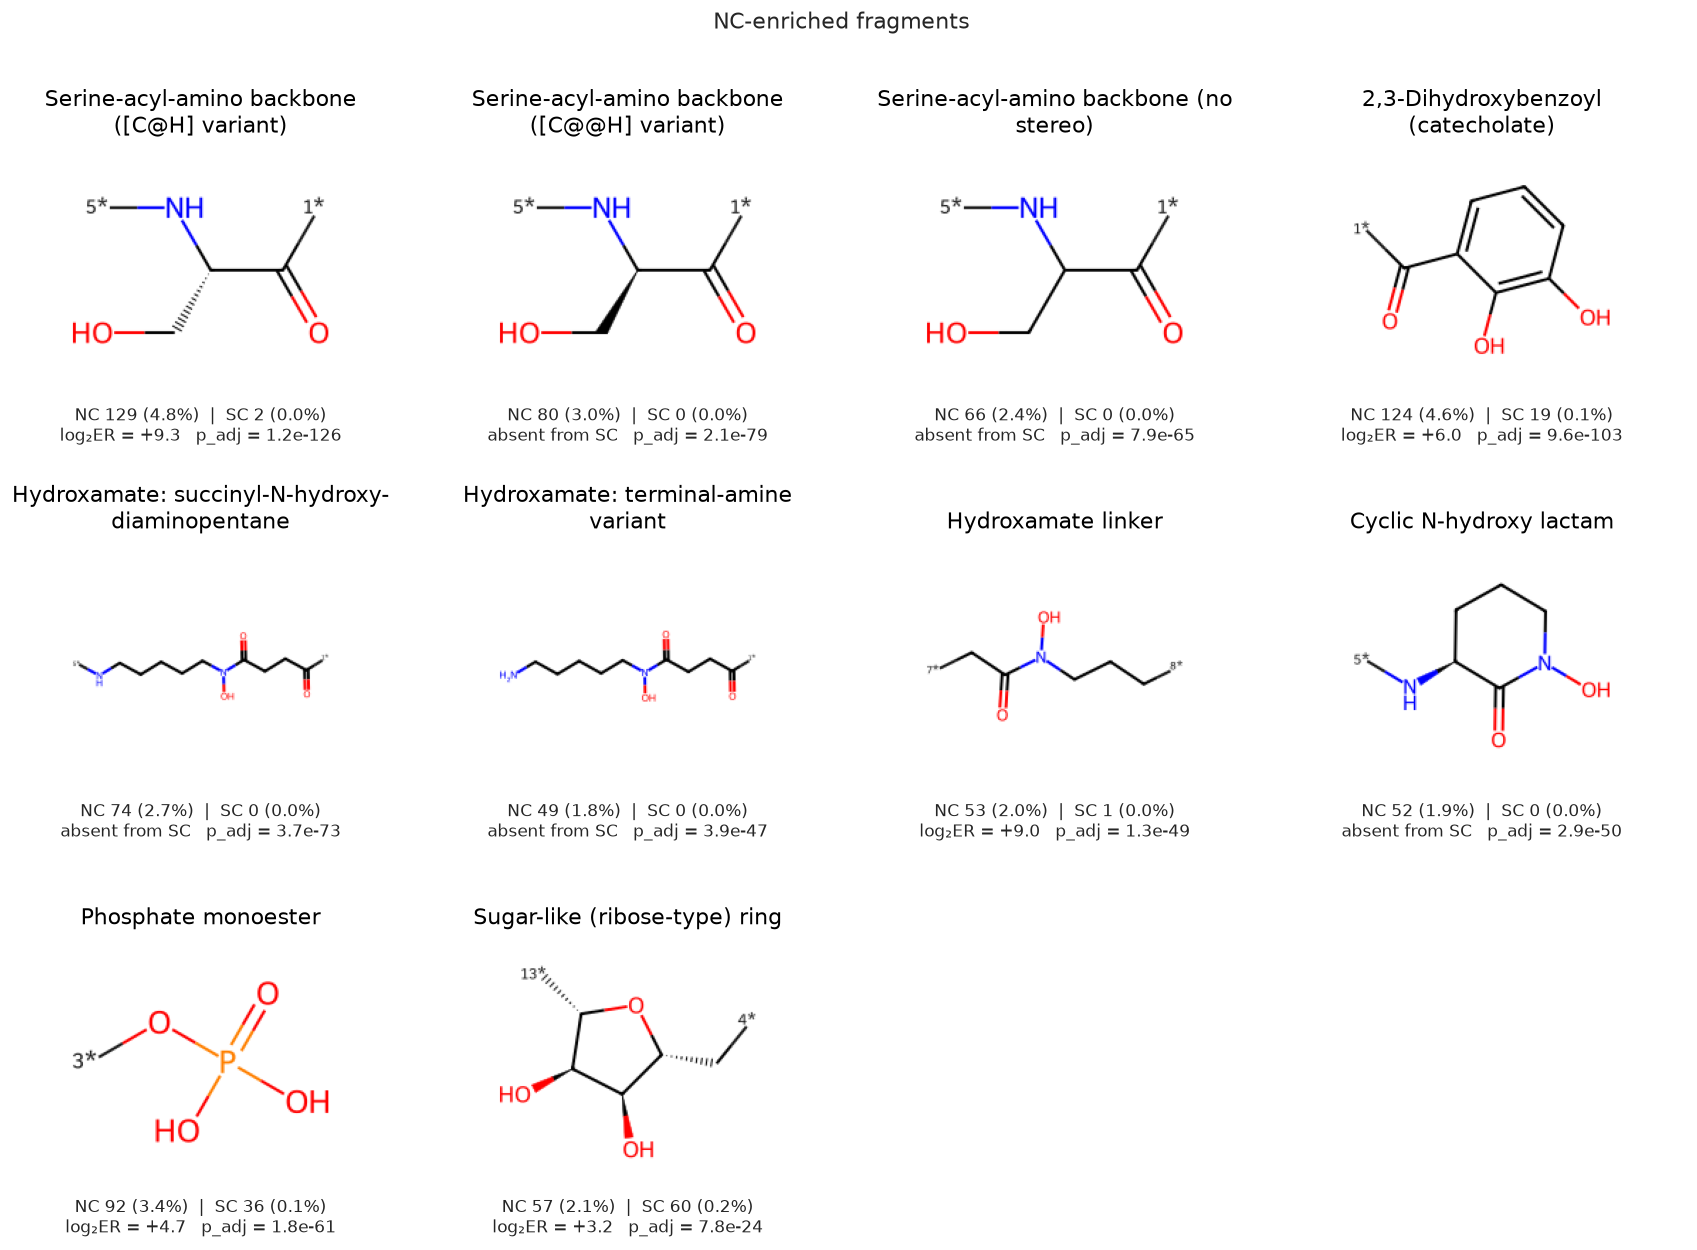

,label,fragment,NC_mols,NC_%,SC_mols,SC_%,log2_ER,p_adj,significant
0,Serine-acyl-amino backbone ([C@H] variant),[1*]C(=O)[C@H](CO)N[5*],129,4.77,2,0.01,9.32,1.153788e-126,True
1,Serine-acyl-amino backbone ([C@@H] variant),[1*]C(=O)[C@@H](CO)N[5*],80,2.96,0,0.00,23.21,2.074804e-79,True
2,Serine-acyl-amino backbone (no stereo),[1*]C(=O)C(CO)N[5*],66,2.44,0,0.00,22.93,7.881532e-65,True
3,"2,3-Dihydroxybenzoyl (catecholate)",[1*]C(=O)c1cccc(O)c1O,124,4.59,19,0.06,6.02,9.578467e-103,True
4,Hydroxamate: succinyl-N-hydroxy-diaminopentane,[1*]C(=O)CCC(=O)N(O)CCCCCN[5*],74,2.74,0,0.00,23.10,3.685961e-73,True
5,Hydroxamate: terminal-amine variant,[1*]C(=O)CCC(=O)N(O)CCCCCN,49,1.81,0,0.00,22.50,3.870230e-47,True
6,Hydroxamate linker,[7*]CC(=O)N(O)CCC[8*],53,1.96,1,0.00,9.04,1.312457e-49,True
7,Cyclic N-hydroxy lactam,[5*]N[C@H]1CCCN(O)C1=O,52,1.92,0,0.00,22.59,2.929445e-50,True
8,Phosphate monoester,[3*]OP(=O)(O)O,92,3.40,36,0.11,4.66,1.834577e-61,True
9,Sugar-like (ribose-type) ring,[4*]C[C@H]1O[C@@H]([13*])[C@H](O)[C@@H]1O,57,2.11,60,0.18,3.24,7.827305e-24,True


In [12]:
import textwrap
from IPython.display import display

def plot_discussion_fragments(items, title, color, fname, ncols=4):
    """items: list of (label, fragment SMILES). Draws each fragment with its NC/SC statistics
    (from enrich_df) and returns a summary table of the fragments that were found."""
    lookup = enrich_df.set_index("fragment")
    n_nc, n_sc = int(class_counts["NC"]), int(class_counts["SC"])

    found, rows = [], []
    for label, smi in items:
        mol = Chem.MolFromSmiles(smi)
        key = Chem.MolToSmiles(mol, canonical=True) if mol else smi
        if key not in lookup.index:
            print(f"Not found in fragment table, skipped: {label}  ({smi})")
            continue
        r = lookup.loc[key]
        found.append((label, key, r))
        rows.append({
            "label": label, "fragment": key,
            "NC_mols": int(r["NC_count"]), "NC_%": round(100 * r["NC_count"] / n_nc, 2),
            "SC_mols": int(r["SC_count"]), "SC_%": round(100 * r["SC_count"] / n_sc, 2),
            "log2_ER": round(float(r["log2_enrichment"]), 2),
            "p_adj": float(r["pval_adj"]),
            "significant": bool(r["significant"]),
        })
    if not found:
        print("None of the requested fragments were found.")
        return pd.DataFrame()

    nrows = int(np.ceil(len(found) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.5 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (label, key, r) in zip(axes, found):
        ax.imshow(Draw.MolToImage(Chem.MolFromSmiles(key), size=(200, 180)))
        ax.set_title("\n".join(textwrap.wrap(label, 32)), fontsize=13, color=color) #, fontweight="bold"
        a, b = int(r["NC_count"]), int(r["SC_count"])
        if b == 0:
            er = "absent from SC"
        elif a == 0:
            er = "absent from NC"
        else:
            er = f"log\u2082ER = {r['log2_enrichment']:+.1f}"
        stats = (f"NC {a:,} ({100*a/n_nc:.1f}%)  |  SC {b:,} ({100*b/n_sc:.1f}%)\n"
                 f"{er}   p_adj = {r['pval_adj']:.1e}")
        ax.text(0.5, -0.03, stats, transform=ax.transAxes, ha="center", va="top", fontsize=10)
    fig.suptitle(title, fontsize=13) #, fontweight="bold"
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.subplots_adjust(hspace=0.55)
    plt.savefig(fname, bbox_inches="tight", dpi=250)
    plt.show()
    return pd.DataFrame(rows)

# ---- NC-enriched fragments (siderophore-like motifs) -------------------------
nc_discussed = [
    ("Serine-acyl-amino backbone ([C@H] variant)",       "[1*]C(=O)[C@H](CO)N[5*]"),
    ("Serine-acyl-amino backbone ([C@@H] variant)",      "[1*]C(=O)[C@@H](CO)N[5*]"),
    ("Serine-acyl-amino backbone (no stereo)",           "[1*]C(=O)C(CO)N[5*]"),
    ("2,3-Dihydroxybenzoyl (catecholate)",               "[1*]C(=O)c1cccc(O)c1O"),
    ("Hydroxamate: succinyl-N-hydroxy-diaminopentane",   "[1*]C(=O)CCC(=O)N(O)CCCCCN[5*]"),
    ("Hydroxamate: terminal-amine variant",              "[1*]C(=O)CCC(=O)N(O)CCCCCN"),
    ("Hydroxamate linker",                               "[7*]CC(=O)N(O)CCC[8*]"),
    ("Cyclic N-hydroxy lactam",                          "[5*]N[C@H]1CCCN(O)C1=O"),
    ("Phosphate monoester",                              "[3*]OP(=O)(O)O"),
    ("Sugar-like (ribose-type) ring",                    "[4*]C[C@H]1O[C@@H]([13*])[C@H](O)[C@@H]1O"),
]
nc_tab = plot_discussion_fragments(nc_discussed, "NC-enriched fragments",
                                   "#000000", "plots/04c_discussed_nc_fragments.png")
display(nc_tab)

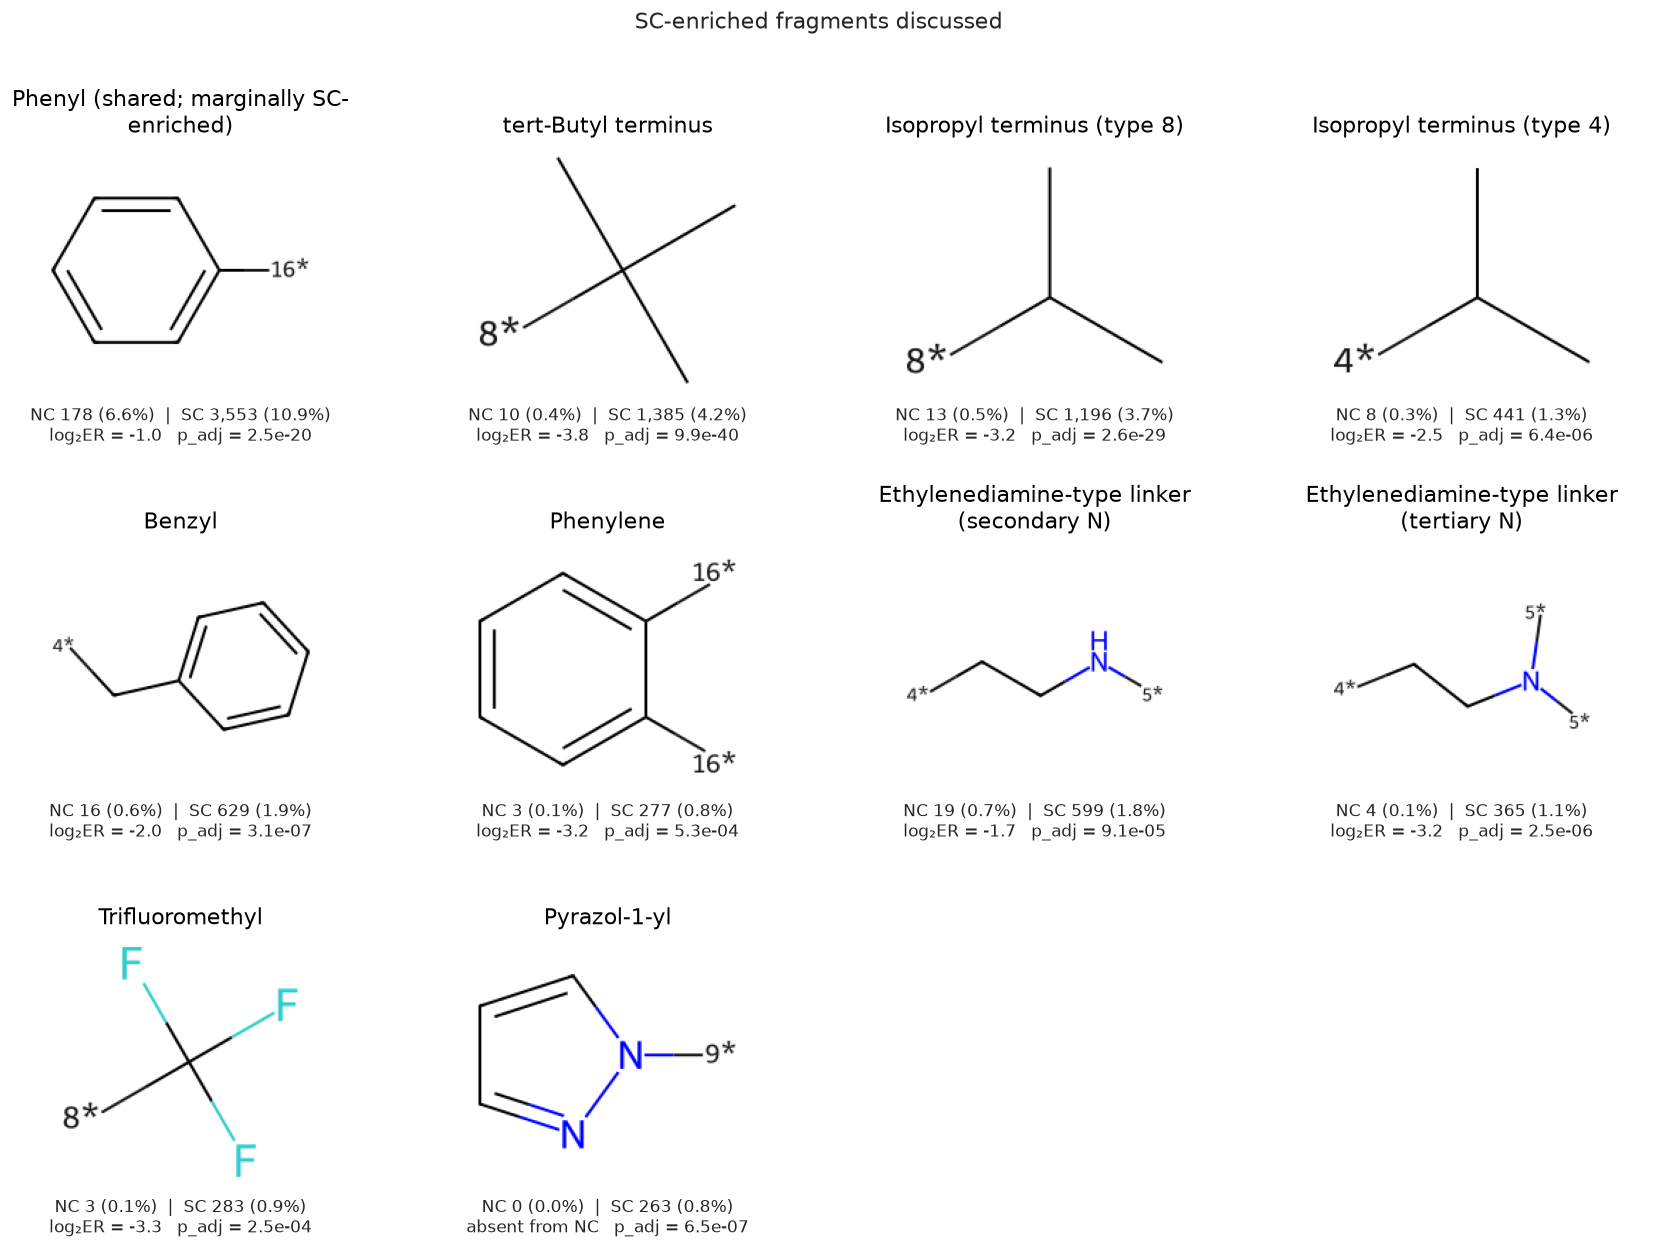

,label,fragment,NC_mols,NC_%,SC_mols,SC_%,log2_ER,p_adj,significant
0,Phenyl (shared; marginally SC-enriched),[16*]c1ccccc1,178,6.59,3553,10.87,-1.01,2.457616e-20,True
1,tert-Butyl terminus,[8*]C(C)(C)C,10,0.37,1385,4.24,-3.80,9.901149e-40,True
2,Isopropyl terminus (type 8),[8*]C(C)C,13,0.48,1196,3.66,-3.21,2.557978e-29,True
3,Isopropyl terminus (type 4),[4*]C(C)C,8,0.30,441,1.35,-2.48,6.357353e-06,True
4,Benzyl,[4*]Cc1ccccc1,16,0.59,629,1.92,-1.99,3.149436e-07,True
5,Phenylene,[16*]c1ccccc1[16*],3,0.11,277,0.85,-3.22,5.320110e-04,True
6,Ethylenediamine-type linker (secondary N),[4*]CCN[5*],19,0.70,599,1.83,-1.67,9.074234e-05,True
7,Ethylenediamine-type linker (tertiary N),[4*]CCN([5*])[5*],4,0.15,365,1.12,-3.20,2.522581e-06,True
8,Trifluoromethyl,[8*]C(F)(F)F,3,0.11,283,0.87,-3.25,2.451755e-04,True
9,Pyrazol-1-yl,[9*]n1cccn1,0,0.00,263,0.80,-29.90,6.498098e-07,True


In [13]:
# ---- SC-enriched fragments (synthetic coordination chemistry) ---------------
sc_discussed = [
    ("Phenyl (shared; marginally SC-enriched)",   "[16*]c1ccccc1"),
    ("tert-Butyl terminus",                        "[8*]C(C)(C)C"),
    ("Isopropyl terminus (type 8)",                "[8*]C(C)C"),
    ("Isopropyl terminus (type 4)",                "[4*]C(C)C"),
    ("Benzyl",                                     "[4*]Cc1ccccc1"),
    ("Phenylene",                                  "[16*]c1ccccc1[16*]"),
    ("Ethylenediamine-type linker (secondary N)",  "[4*]CCN[5*]"),
    ("Ethylenediamine-type linker (tertiary N)",   "[4*]CCN([5*])[5*]"),
    ("Trifluoromethyl",                            "[8*]C(F)(F)F"),
    ("Pyrazol-1-yl",                               "[9*]n1cccn1"),
]
sc_tab = plot_discussion_fragments(sc_discussed, "SC-enriched fragments discussed",
                                   "#000000", "plots/04d_discussed_sc_fragments.png")
display(sc_tab)

### 7c. Enrichment Volcano Plot

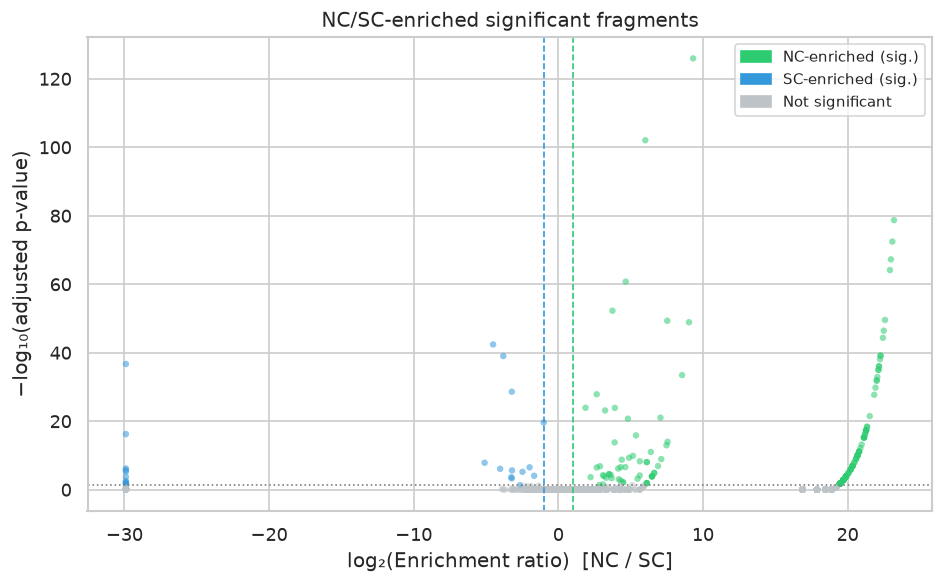

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
colors_map = enrich_df.apply(
    lambda r: "#2ecc71" if r["significant"] and r["log2_enrichment"] > 1
    else "#3498db" if r["significant"] and r["log2_enrichment"] < -1
    else "#bdc3c7", axis=1)
ax.scatter(enrich_df["log2_enrichment"], enrich_df["neg_log10_pval"],
           c=colors_map, alpha=0.55, s=15, linewidths=0)
ax.axvline(1, ls="--", color="#2ecc71", lw=1); ax.axvline(-1, ls="--", color="#3498db", lw=1)
ax.axhline(-np.log10(0.05), ls=":", color="grey", lw=1)
ax.set_xlabel("log₂(Enrichment ratio)  [NC / SC]")
ax.set_ylabel("−log₁₀(adjusted p-value)")
ax.set_title("NC/SC-enriched significant fragments") #, fontweight="bold"
nc_patch = mpatches.Patch(color="#2ecc71", label="NC-enriched (sig.)")
sc_patch = mpatches.Patch(color="#3498db", label="SC-enriched (sig.)")
ns_patch = mpatches.Patch(color="#bdc3c7", label="Not significant")
ax.legend(handles=[nc_patch, sc_patch, ns_patch], fontsize=9)
plt.tight_layout(); plt.savefig("plots/05_volcano.png", bbox_inches="tight"); plt.show()


### 7d. Fragment Diversity (Tanimoto distance distribution)

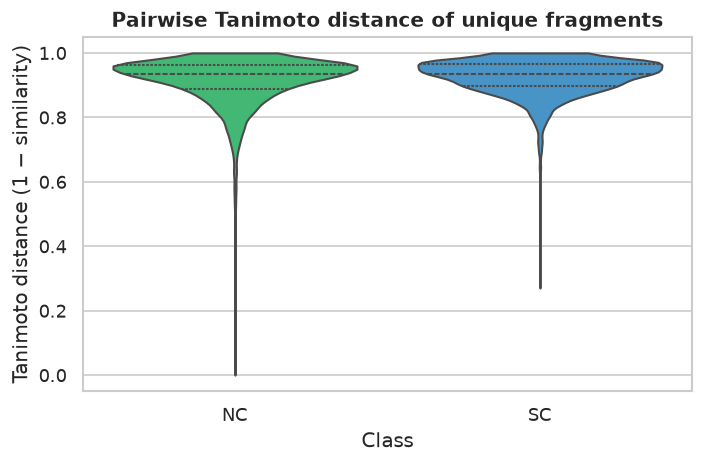

Class  Unique fragments  Mean Tanimoto dist   Median  10th pct  90th pct
   NC              2980            0.914912 0.934426  0.826087  0.978261
   SC             29569            0.925551 0.935897  0.857143  0.981132


In [15]:
# Random sub-sample of the pairwise distances (the arrays are ordered by fragment index,
# so slicing the first N would only show pairs involving the first few fragments).
rng = np.random.default_rng(SEED)
def subsample(arr, n=5000):
    return arr if len(arr) <= n else rng.choice(arr, n, replace=False)

nc_plot, sc_plot = subsample(nc_div), subsample(sc_div)
div_data = pd.DataFrame({
    "Tanimoto distance": np.concatenate([nc_plot, sc_plot]),
    "Class": ["NC"] * len(nc_plot) + ["SC"] * len(sc_plot)
})
fig, ax = plt.subplots(figsize=(6, 4))
sns.violinplot(data=div_data, x="Class", y="Tanimoto distance", hue="Class",
               palette={"NC": "#2ecc71", "SC": "#3498db"}, inner="quartile",
               density_norm="width", ax=ax, cut=0, legend=False)
ax.set_title("Pairwise Tanimoto distance of unique fragments", fontweight="bold")
ax.set_ylabel("Tanimoto distance (1 − similarity)")
plt.tight_layout(); plt.savefig("plots/06_diversity_violin.png", bbox_inches="tight"); plt.show()
print(div_summary.to_string(index=False))

### 7e. BRICS Fragments per Molecule

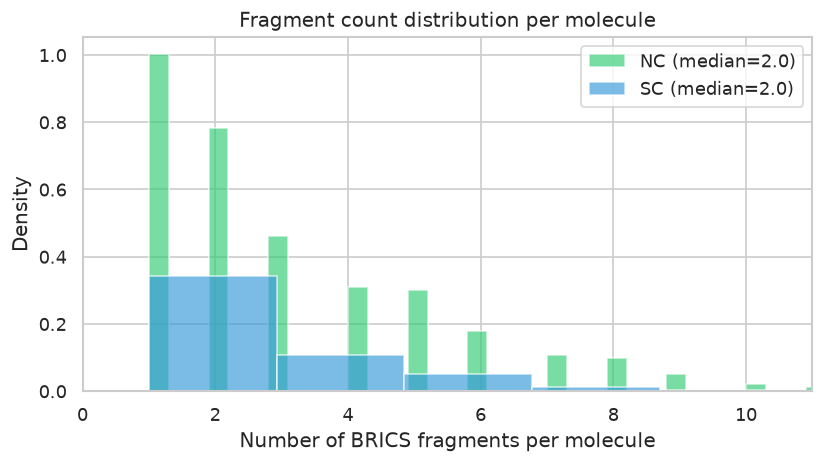

In [16]:
df["n_frags"] = df["brics_frags"].apply(len)
fig, ax = plt.subplots(figsize=(7, 4))
for cls, col in [("NC", "#2ecc71"), ("SC", "#3498db")]:
    vals = df.loc[df["class"] == cls, "n_frags"]
    ax.hist(vals, bins=40, alpha=0.65, color=col, density=True,
            label=f"{cls} (median={vals.median():.1f})")
ax.set_xlabel("Number of BRICS fragments per molecule")
ax.set_ylabel("Density")
ax.set_title("Fragment count distribution per molecule") #, fontweight="bold"
ax.legend(); ax.set_xlim(0, df["n_frags"].quantile(0.99) + 2)
plt.tight_layout(); plt.savefig("plots/07_frags_per_mol.png", bbox_inches="tight"); plt.show()


### 7f. PCA of Top-3000 Fragment Fingerprints

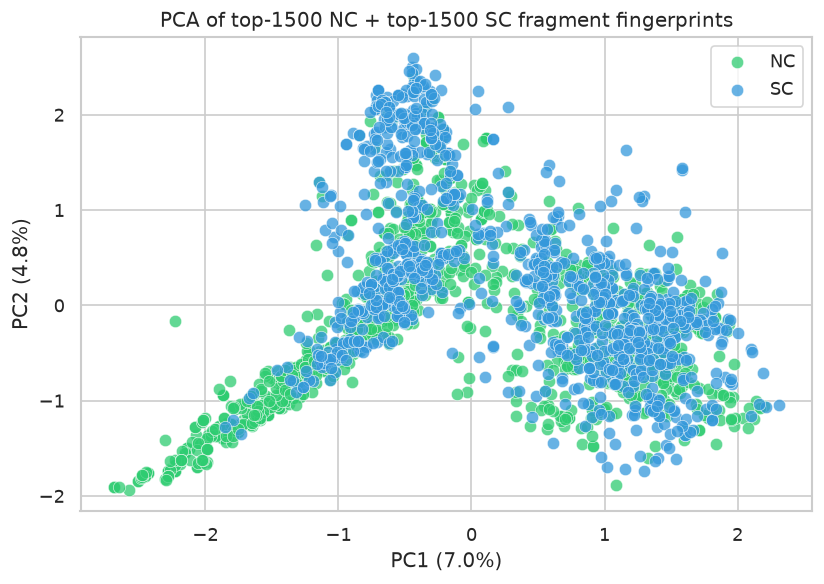

In [17]:
# Take top 1500 NC + top 1500 SC fragments by frequency
top_nc = [f for f, _ in nc_counter.most_common(1500) if f in fp_dict]
top_sc = [f for f, _ in sc_counter.most_common(1500) if f in fp_dict]
pca_frags = list(dict.fromkeys(top_nc + top_sc))  # preserve order, no dups
pca_labels = ["NC" if f in nc_unique else "SC" for f in pca_frags]

X = np.array([list(fp_dict[f]) for f in pca_frags])
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(7, 5))
for cls, col, marker in [("NC", "#2ecc71", "o"), ("SC", "#3498db", "o")]:
    mask = np.array([l == cls for l in pca_labels])
    ax.scatter(coords[mask, 0], coords[mask, 1], c=col, marker=marker,
               alpha=0.75, s=55, label=cls, edgecolors="white", linewidths=0.4)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("PCA of top-1500 NC + top-1500 SC fragment fingerprints") #, fontweight="bold"
ax.legend(); plt.tight_layout()
plt.savefig("plots/08_pca_fragments.png", bbox_inches="tight"); plt.show()


### 7g. Tanimoto Similarity Heatmap (Top-50 Fragments per Class)

In [ ]:
'''top50_nc = [f for f, _ in nc_counter.most_common(50) if f in fp_dict]
top50_sc = [f for f, _ in sc_counter.most_common(50) if f in fp_dict]
heat_frags = list(dict.fromkeys(top50_nc + top50_sc))
heat_labels = ["NC" if f in nc_unique else "SC" for f in heat_frags]

fps_heat = [fp_dict[f] for f in heat_frags]
n = len(fps_heat)
sim_mat = np.eye(n)
for i in range(n):
    row = DataStructs.BulkTanimotoSimilarity(fps_heat[i], fps_heat)
    sim_mat[i] = row

label_colors = ["#2ecc71" if l == "NC" else "#3498db" for l in heat_labels]

g = sns.clustermap(sim_mat, cmap="viridis", vmin=0, vmax=1,
                   row_colors=label_colors, col_colors=label_colors,
                   figsize=(10, 9), xticklabels=False, yticklabels=False)
g.ax_heatmap.set_title("Fragment Tanimoto similarity (top-50 NC + SC)", pad=60) #, fontweight="bold"
nc_patch = mpatches.Patch(color="#2ecc71", label="NC"); sc_patch = mpatches.Patch(color="#3498db", label="SC")
g.ax_heatmap.legend(handles=[nc_patch, sc_patch], loc="upper left",
                    bbox_to_anchor=(1.05, 1.15), title="Class")
plt.savefig("plots/09_tanimoto_heatmap.png", bbox_inches="tight"); plt.show()
'''


In [19]:
# Save necessary reports as CSV files for further analysis or sharing
os.mkdir("reports") if not os.path.exists("reports") else None
df.to_csv("reports/processed_compounds.csv", index=False)
enrich_df.to_csv("reports/fragment_enrichment.csv", index=False) 
# Save the diversity summary table
div_summary.to_csv("reports/diversity_summary.csv", index=False) 
# Save PCA coordinates for top fragments
pca_df = pd.DataFrame(coords, columns=["PC1", "PC2"])
pca_df["fragment"] = pca_frags
pca_df["class"] = pca_labels
pca_df.to_csv("reports/pca_coordinates.csv", index=False)  


## 8. Analysis Summary

In [20]:
nc_n = class_counts.get("NC", 0)
sc_n = class_counts.get("SC", 0)
print(f"{'='*60}")
print(f"  FRAGMENT-BASED ANALYSIS SUMMARY  –  data from Feeney et al. 2026")
print(f"{'='*60}")
print(f"  Total unique molecules (post-dedup):  {nc_n + sc_n:,}")
print(f"    Natural Product chelators (NC):     {nc_n:,}  ({nc_n/(nc_n+sc_n)*100:.1f}%)")
print(f"    Synthetic chelators (SC):           {sc_n:,}  ({sc_n/(nc_n+sc_n)*100:.1f}%)")
print(f"  Cross-class duplicates removed:       {len(cross_dups):,}")
print(f"  Excluded at BRICS step (skipped/failed): {n_brics_excluded:,}")
print()
print(f"  BRICS fragments")
print(f"    NC unique fragments:  {len(nc_unique):,}")
print(f"    SC unique fragments:  {len(sc_unique):,}")
print(f"    Shared:              {len(shared):,} ({len(shared)/len(nc_unique|sc_unique)*100:.1f}% of all)")
print(f"    NC-exclusive:        {len(nc_unique - sc_unique):,}")
print(f"    SC-exclusive:        {len(sc_unique - nc_unique):,}")
print()
print(f"  Enrichment (Fisher's exact + Bonferroni, α=0.05)")
print(f"    NC-enriched fragments:  {len(nc_enriched):,}")
print(f"    SC-enriched fragments:  {len(sc_enriched):,}")
print()
print(f"  Fragment diversity (mean pairwise Tanimoto distance)")
print(f"    NC:  {nc_div.mean():.4f}")
print(f"    SC:  {sc_div.mean():.4f}")
print(f"{'='*60}")


  FRAGMENT-BASED ANALYSIS SUMMARY  –  data from Feeney et al. 2026
  Total unique molecules (post-dedup):  35,403
    Natural Product chelators (NC):     2,703  (7.6%)
    Synthetic chelators (SC):           32,700  (92.4%)
  Cross-class duplicates removed:       7
  Excluded at BRICS step (skipped/failed): 6

  BRICS fragments
    NC unique fragments:  2,980
    SC unique fragments:  29,569
    Shared:              776 (2.4% of all)
    NC-exclusive:        2,204
    SC-exclusive:        28,793

  Enrichment (Fisher's exact + Bonferroni, α=0.05)
    NC-enriched fragments:  161
    SC-enriched fragments:  24

  Fragment diversity (mean pairwise Tanimoto distance)
    NC:  0.9149
    SC:  0.9256
